File src/praproses.py berhasil dibuat dan dilengkapi!

--- L5.2: Rerata KB Sebelum dan Sesudah Praproses ---
                KB_sebelum  KB_sesudah
kondisi                               
bayangan              5.67        9.19
gelap                 8.55       14.97
kontras_rendah        3.58        5.68
normal                8.62       10.26
terang                6.28        6.78

--- L5.3: Uji Bercak Palsu ---

Simpangan Baku Daun Sehat (Jangan sampai meroket):
                Std_sebelum  Std_sesudah
kondisi                                 
bayangan              14.77         9.91
gelap                  9.39         5.02
kontras_rendah         9.22         8.43
normal                10.99         8.44
terang                10.86        10.96

Menampilkan Panel Uji Bercak Palsu...


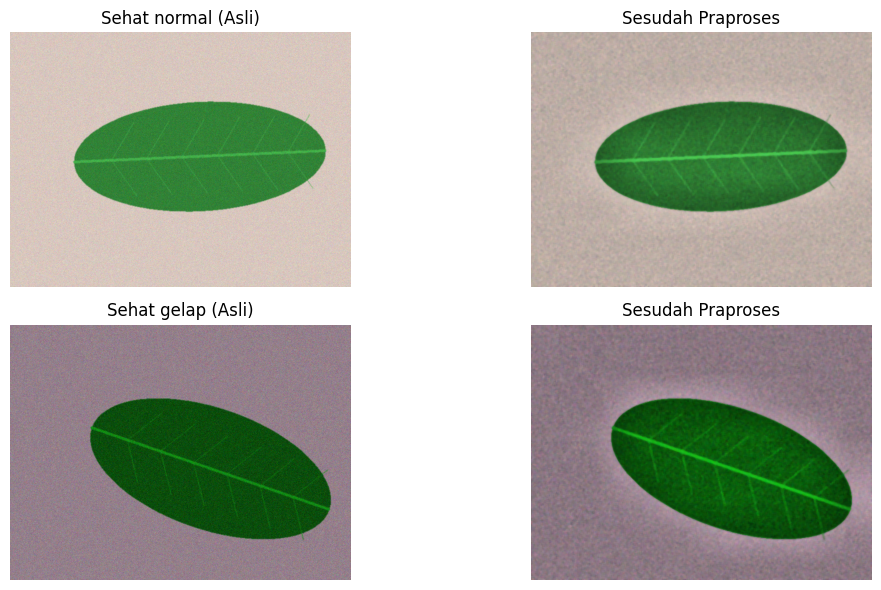

In [3]:
import sys, os, json
import cv2, numpy as np, pandas as pd, matplotlib.pyplot as plt

sys.path.append('/content/drive/MyDrive/simuteh-2330511031/src')
os.chdir('/content/drive/MyDrive/simuteh-2330511031/notebook')

# ---------------- L5.1: Membuat File src/praproses.py secara Otomatis ----------------
kode_praproses = '''"""praproses.py: rangkaian praproses SIMUTEH (dipakai ulang mulai P5)."""
import json
import cv2
import numpy as np

PARAM_BAWAAN = {
    "lebar": 640,
    "gamma": 1.0,
    "clahe_clip": 2.0,
    "clahe_tile": 8,
    "penapis": "median",
    "kernel": 5,
    "sigma": 1.0,
    "tajam_k": 0.0,
}

def praproses(img_bgr, p=None):
    """Urutan: ubah ukuran -> gamma -> CLAHE kanal V -> redam derau -> tajamkan."""
    p = {**PARAM_BAWAAN, **(p or {})}

    # 1: Ubah ukuran agar lebar = p["lebar"], rasio aspek tetap
    h, w = img_bgr.shape[:2]
    rasio = p["lebar"] / w
    img = cv2.resize(img_bgr, (p["lebar"], int(h * rasio)), interpolation=cv2.INTER_AREA)

    # 2: Koreksi Gamma
    if p["gamma"] != 1.0:
        lut = np.array([255 * (i / 255) ** p["gamma"] for i in range(256)]).clip(0, 255).astype(np.uint8)
        img = cv2.LUT(img, lut)

    # 3: CLAHE Kanal V
    if p["clahe_clip"] > 0:
        hsv = cv2.cvtColor(img, cv2.COLOR_BGR2HSV)
        clahe = cv2.createCLAHE(clipLimit=p["clahe_clip"], tileGridSize=(p["clahe_tile"], p["clahe_tile"]))
        hsv[:, :, 2] = clahe.apply(hsv[:, :, 2])
        img = cv2.cvtColor(hsv, cv2.COLOR_HSV2BGR)

    # 4: Redam derau
    if p["penapis"] == "median":
        img = cv2.medianBlur(img, p["kernel"])
    elif p["penapis"] == "gaussian":
        img = cv2.GaussianBlur(img, (p["kernel"], p["kernel"]), p["sigma"])

    # 5: Tajamkan (Unsharp Masking)
    if p["tajam_k"] > 0:
        blur = cv2.GaussianBlur(img, (5, 5), 1.0)
        img = cv2.addWeighted(img, 1 + p["tajam_k"], blur, -p["tajam_k"], 0)

    return img

def simpan_param(p, path="../hasil/param_praproses.json"):
    with open(path, "w") as f:
        json.dump({**PARAM_BAWAAN, **p}, f, indent=2)
'''
with open('../src/praproses.py', 'w') as f: f.write(kode_praproses)
print("File src/praproses.py berhasil dibuat dan dilengkapi!")

# ---------------- L5.2: Evaluasi Kuantitatif Rangkaian Praproses ----------------
from praproses import praproses, simpan_param
from utils_cv import baca, tampil, kontras_bercak

# Parameter Final: Menggunakan parameter bawaan di atas (Median kernel 5, CLAHE clip 2.0)
param = {"gamma": 1.0, "clahe_clip": 2.0, "penapis": "median", "kernel": 5, "tajam_k": 0.0}
simpan_param(param, "../hasil/param_praproses.json")
KANAL = 2 # Menggunakan Kanal Merah (R) yang terbukti terbaik di B2.

label = pd.read_csv("../data/sintetis/label.csv")
baris = []
for _, d in label[label.kelas != "sehat"].iterrows():
    img = baca(f"../data/sintetis/citra/{d.nama_file}")
    md = cv2.imread(f"../data/sintetis/mask_daun/{d.nama_file}", 0)
    mb = cv2.imread(f"../data/sintetis/mask_bercak/{d.nama_file}", 0)

    # KB Asli (sebelum resize)
    kb_seb = kontras_bercak(img[:, :, KANAL], md, mb)

    # Resize Mask agar sesuai dengan citra praproses (lebar 640)
    h, w = img.shape[:2]
    rasio = 640 / w
    md_kecil = cv2.resize(md, (640, int(h * rasio)), interpolation=cv2.INTER_NEAREST)
    mb_kecil = cv2.resize(mb, (640, int(h * rasio)), interpolation=cv2.INTER_NEAREST)

    # KB Sesudah Praproses
    out = praproses(img, param)
    kb_ses = kontras_bercak(out[:, :, KANAL], md_kecil, mb_kecil)
    baris.append([d.kondisi_cahaya, kb_seb, kb_ses])

evaluasi = pd.DataFrame(baris, columns=["kondisi", "KB_sebelum", "KB_sesudah"])
print("\n--- L5.2: Rerata KB Sebelum dan Sesudah Praproses ---")
print(evaluasi.groupby("kondisi").mean().round(2))


# ---------------- L5.3: Uji Bercak Palsu pada Kelas Sehat ----------------
print("\n--- L5.3: Uji Bercak Palsu ---")
baris_sehat = []
contoh_citra = []
contoh_out = []
label_kond = []

for _, d in label[label.kelas == "sehat"].iterrows():
    img = baca(f"../data/sintetis/citra/{d.nama_file}")
    md = cv2.imread(f"../data/sintetis/mask_daun/{d.nama_file}", 0)

    kanal_seb = img[:, :, KANAL].astype(float)
    std_seb = kanal_seb[md > 0].std()

    out = praproses(img, param)
    h, w = img.shape[:2]; rasio = 640 / w
    md_kecil = cv2.resize(md, (640, int(h * rasio)), interpolation=cv2.INTER_NEAREST)

    kanal_ses = out[:, :, KANAL].astype(float)
    std_ses = kanal_ses[md_kecil > 0].std()
    baris_sehat.append([d.kondisi_cahaya, std_seb, std_ses])

    # Ambil 1 contoh per kondisi untuk divisualisasikan
    if d.kondisi_cahaya not in label_kond:
        label_kond.append(d.kondisi_cahaya)
        contoh_citra.append(img)
        contoh_out.append(out)

eval_sehat = pd.DataFrame(baris_sehat, columns=["kondisi", "Std_sebelum", "Std_sesudah"])
print("\nSimpangan Baku Daun Sehat (Jangan sampai meroket):")
print(eval_sehat.groupby("kondisi").mean().round(2))

print("\nMenampilkan Panel Uji Bercak Palsu...")
# Tampilkan 4 contoh (2 kondisi pertama, sebelum vs sesudah)
tampil([contoh_citra[0], contoh_out[0], contoh_citra[1], contoh_out[1]],
       [f"Sehat {label_kond[0]} (Asli)", "Sesudah Praproses",
        f"Sehat {label_kond[1]} (Asli)", "Sesudah Praproses"],
       baris=2, ukuran=(12, 6))

In [4]:
from google.colab import drive
import os
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
import os
os.chdir('/content/drive/MyDrive/simuteh-2330511031')

# 1. Tarik README.md yang baru kamu buat di web GitHub agar sinkron ke Drive
!git pull origin main

# 2. Atur ulang identitas (wajib setiap sesi baru)
!git config --global user.email "nazwa.syafia2016@gmail.com"
!git config --global user.name "nazwasm"

# 3. Tambahkan semua perubahan (B1 yang diedit, B2-B5, dan file lainnya)
!git add .

# 4. Bungkus semua perubahan
!git commit -m "Finalisasi seluruh notebook B1-B5 dan integrasi praproses"

# 5. Kirim seluruh notebook ke server GitHub
!git push origin main

# 6. Beri stempel/tag versi pada kondisi saat ini
!git tag v0.1-praproses

# 7. Kirim tag tersebut ke GitHub
!git push --tags

remote: Enumerating objects: 3, done.
remote: Counting objects: 100% (3/3), done.
remote: Compressing objects: 100% (3/3), done.
remote: Total 3 (delta 0), reused 0 (delta 0), pack-reused 0 (from 0)
Unpacking objects: 100% (3/3), 1.80 KiB | 7.00 KiB/s, done.
From https://github.com/nazwasm/simuteh-2330511031
 * branch            main       -> FETCH_HEAD
   5a4950d..d54dd6e  main       -> origin/main
Updating 5a4950d..d54dd6e
